<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan2/latihan2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, learning_curve, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [ ]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Ukuran dataset:", df.shape)
print(df.head())

# Ubah TotalCharges menjadi numerik
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

Ukuran dataset: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV Streaming

In [ ]:
# customerID tidak digunakan sebagai fitur
X = df.drop(columns=["Churn", "customerID"])

# Target Churn:
# No = 0
# Yes = 1
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("\nJumlah data:")
print(y.value_counts())



Jumlah data:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("\nData training:", X_train.shape)
print("Data testing :", X_test.shape)



Data training: (5634, 19)
Data testing : (1409, 19)


In [ ]:
kolom_kategorikal = X.select_dtypes(
    include="object"
).columns.tolist()

kolom_numerik = X.select_dtypes(
    exclude="object"
).columns.tolist()

preprocessing = ColumnTransformer([
    (
        "numerik",
        SimpleImputer(strategy="median"),
        kolom_numerik
    ),
    (
        "kategorikal",
        Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),
            (
                "onehot",
                OneHotEncoder(handle_unknown="ignore")
            )
        ]),
        kolom_kategorikal
    )
])

In [ ]:
kedalaman = [1, 4, None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

hasil = {}

for depth in kedalaman:

    model = Pipeline([
        ("preprocessing", preprocessing),
        (
            "tree",
            DecisionTreeClassifier(
                max_depth=depth,
                random_state=42
            )
        )
    ])

    # Latih model
    model.fit(X_train, y_train)

    # Akurasi training dan testing
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    akurasi_train = accuracy_score(
        y_train, pred_train
    )

    akurasi_test = accuracy_score(
        y_test, pred_test
    )

    # Learning curve
    train_sizes, train_scores, valid_scores = learning_curve(
        model,
        X_train,
        y_train,
        train_sizes=np.linspace(0.1, 1.0, 5),
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    hasil[depth] = {
        "train_sizes": train_sizes,
        "train_mean": train_scores.mean(axis=1),
        "valid_mean": valid_scores.mean(axis=1),
        "akurasi_train": akurasi_train,
        "akurasi_test": akurasi_test
    }


HASIL AKURASI
Depth 1: Train = 0.735, Test = 0.735
Depth 4: Train = 0.797, Test = 0.792
Depth ∞: Train = 0.998, Test = 0.729


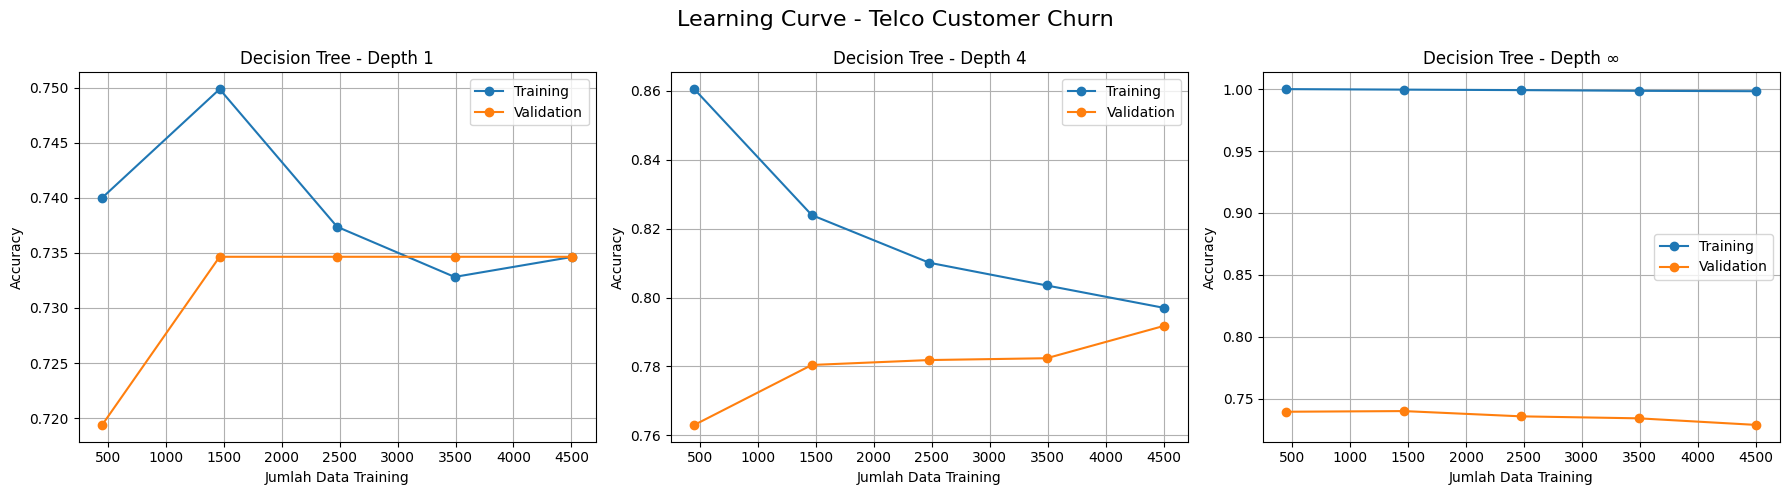

In [ ]:
print("\n================================")
print("HASIL AKURASI")
print("================================")

for depth in kedalaman:

    nama_depth = depth if depth is not None else "∞"

    print(
        f"Depth {nama_depth}: "
        f"Train = {hasil[depth]['akurasi_train']:.3f}, "
        f"Test = {hasil[depth]['akurasi_test']:.3f}"
    )

# ============================================
# 7. PLOT LEARNING CURVE
# ============================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, depth in zip(axes, kedalaman):

    train_sizes = hasil[depth]["train_sizes"]
    train_mean = hasil[depth]["train_mean"]
    valid_mean = hasil[depth]["valid_mean"]

    nama_depth = depth if depth is not None else "∞"

    ax.plot(
        train_sizes,
        train_mean,
        marker="o",
        label="Training"
    )

    ax.plot(
        train_sizes,
        valid_mean,
        marker="o",
        label="Validation"
    )

    ax.set_title(
        f"Decision Tree - Depth {nama_depth}"
    )

    ax.set_xlabel("Jumlah Data Training")
    ax.set_ylabel("Accuracy")

    ax.grid(True)
    ax.legend()

plt.suptitle(
    "Learning Curve - Telco Customer Churn",
    fontsize=16
)

plt.tight_layout()
plt.show()